In [1]:
!pip install -q kagglehub

In [2]:
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [5]:
# Binary     : "arunrk7/surface-crack-detection"
DATASET = "arunrk7/surface-crack-detection"

root = kagglehub.dataset_download(DATASET)
print("Data tersimpan di:", root)

100%|██████████| 233M/233M [00:06<00:00, 38.5MB/s]

Extracting files...


Data tersimpan di: /root/.cache/kagglehub/datasets/arunrk7/surface-crack-detection/versions/1


In [6]:
rows = []
for dirpath, _, files in os.walk(root):
    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            rows.append({"path": os.path.join(dirpath, f),
                         "label": os.path.basename(dirpath)})

df = pd.DataFrame(rows)
df.head()

,path,label
0,/root/.cache/kagglehub/datasets/arunrk7/surfac...,Negative
1,/root/.cache/kagglehub/datasets/arunrk7/surfac...,Negative
2,/root/.cache/kagglehub/datasets/arunrk7/surfac...,Negative
3,/root/.cache/kagglehub/datasets/arunrk7/surfac...,Negative
4,/root/.cache/kagglehub/datasets/arunrk7/surfac...,Negative


In [7]:
print("Jumlah data  :", len(df))
print("Jumlah kolom :", df.shape[1])
print("Nama kolom   :", list(df.columns))
print("Data kosong  :", df.isnull().sum().sum())
df.info()

Jumlah data  : 40000
Jumlah kolom : 2
Nama kolom   : ['path', 'label']
Data kosong  : 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   path    40000 non-null  object
 1   label   40000 non-null  object
dtypes: object(2)
memory usage: 625.1+ KB


In [8]:
print("FITUR : kolom 'path' (isi piksel gambar)")
print("LABEL : kolom 'label'")

n = df["label"].nunique()
print("Jumlah kelas:", n)
print("Jenis       :", "BINARY" if n == 2 else "MULTICLASS")

FITUR : kolom 'path' (isi piksel gambar)
LABEL : kolom 'label'
Jumlah kelas: 2
Jenis       : BINARY


In [9]:
df["label"].value_counts()

,count
label,
Negative,20000
Positive,20000


In [10]:
img = Image.open(df["path"][0])
w, h = img.size
c = len(img.getbands())
print(f"Ukuran gambar : {w} x {h} x {c}")
print(f"Jumlah fitur  : {w*h*c} piksel")

Ukuran gambar : 227 x 227 x 3
Jumlah fitur  : 154587 piksel


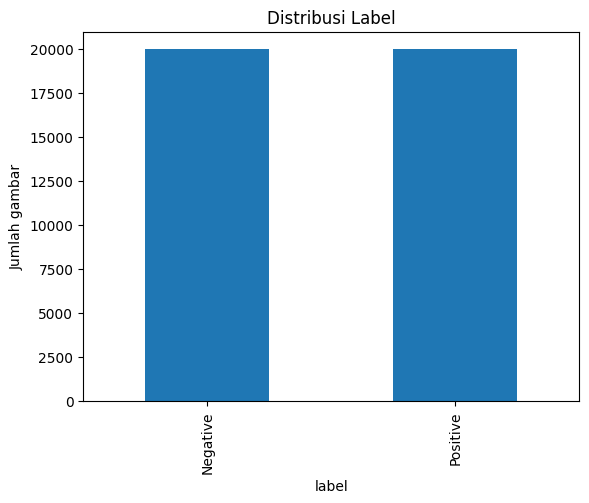

In [11]:
df["label"].value_counts().plot(kind="bar", title="Distribusi Label")
plt.ylabel("Jumlah gambar")
plt.show()

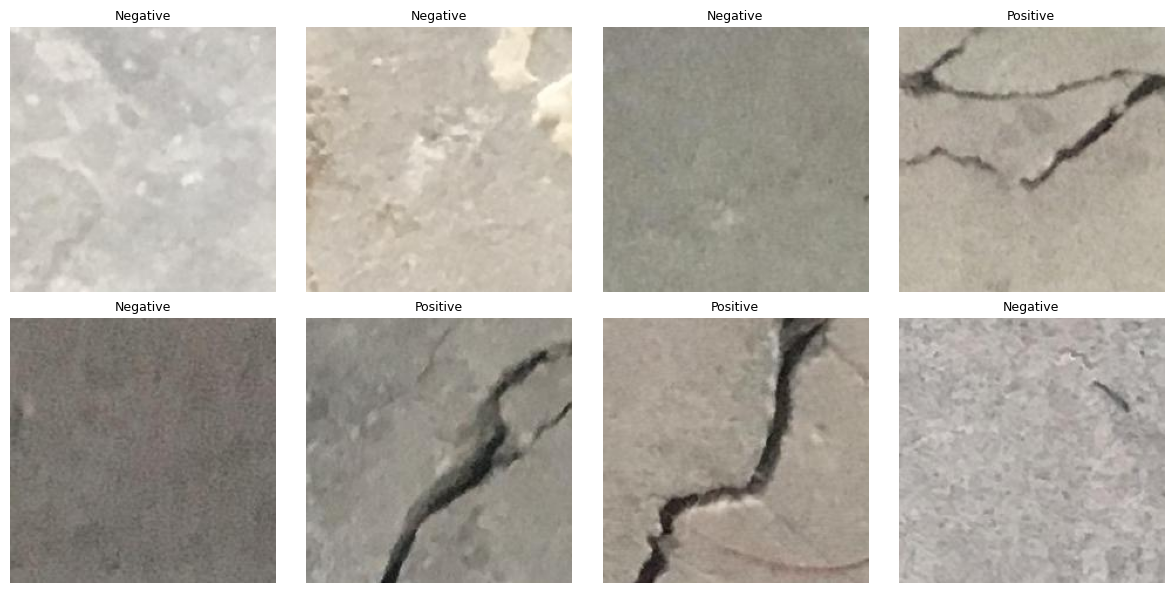

In [12]:
sampel = df.sample(8, random_state=1)

plt.figure(figsize=(12, 6))
for i, (_, r) in enumerate(sampel.iterrows()):
    plt.subplot(2, 4, i + 1)
    plt.imshow(Image.open(r["path"]))
    plt.title(r["label"], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
https://www.kaggle.com/datasets/arunrk7/surface-crack-detection